# Práctica 2: Regresión lineal múltiple
## Predicción del costo anual de un seguro médico

**Universidad:** Universidad Autónoma Tomás Frías  
**Carrera:** Ingeniería Informática  
**Materia:** INF672 — Machine Learning  
**Estudiante:** Limberth Cordova Mamani  
**Fecha:** 6 de octubre de 2026

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [4]:
df = pd.read_csv("insurance.csv")

print("Dimensiones:", df.shape)
display(df.head())
df.info()

Dimensiones: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


### Respuestas

**¿Cuántos asegurados y cuántas columnas tiene el dataset?**

El dataset tiene 1338 asegurados y 7 columnas.

**¿Qué representa una fila?**

Cada fila representa a un asegurado. Contiene sus características
personales y el costo médico anual registrado.

**¿Qué columnas contienen texto y cuáles contienen números?**

Las columnas que contienen texto son sex, smoker y region.

Las columnas numéricas son age, bmi, children y charges. La edad y
el número de hijos son enteros, mientras que el IMC y el costo
contienen valores decimales.

**¿Cuál es la variable que queremos predecir?**

La variable objetivo es charges, que representa el costo médico anual
en dólares estadounidenses.

Además, df.info() muestra que todas las columnas tienen 1338 valores
no nulos, por lo que no hay datos faltantes.

## Paso 03. Preparar los datos para el modelo

Separo el costo anual de las variables de entrada. Después convierto
las columnas categóricas en variables numéricas mediante one-hot encoding.

In [6]:
y = df["charges"]

X = df.drop(columns=["charges"])

X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Columnas de entrada:")
print(list(X.columns))

print("\nCantidad de columnas:", X.shape[1])

Columnas de entrada:
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Cantidad de columnas: 8


In [7]:

X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


### Respuestas

**¿En cuántas columnas se convirtieron las 6 variables originales?**

Las 6 variables originales se convirtieron en 8 columnas:

- age
- bmi
- children
- sex_male
- smoker_yes
- region_northwest
- region_southeast
- region_southwest

**¿Qué categoría quedó como referencia?**

| Variable | Categoría de referencia |
|---|---|
| sex | female |
| smoker | no |
| region | northeast |

**¿Qué hace drop_first=True?**

Elimina una columna indicadora de cada variable categórica. Esto evita
que las columnas indicadoras y el intercepto tengan una dependencia
lineal exacta.

**¿Por qué no se pierde información?**

La categoría eliminada se puede identificar cuando las demás columnas
de esa variable tienen valor cero.

Por ejemplo, sex_male igual a cero representa female. Si las tres
columnas de región tienen valor cero, la región es northeast.

## Paso 04. Dividir en entrenamiento y prueba

Reservo el 20 % de los datos para evaluar el modelo y utilizo el resto
para entrenarlo. Fijo random_state en 42 para repetir la misma división
en futuras ejecuciones.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

Registros de entrenamiento: 1070
Registros de prueba: 268


### Respuestas

**Tamaño de cada conjunto**

El conjunto de entrenamiento contiene 1070 registros y el conjunto
de prueba contiene 268 registros.

**¿Por qué no se debe evaluar con los mismos datos del entrenamiento?**

Porque el modelo ya utilizó esos datos para ajustar sus coeficientes.
Evaluarlo solamente con ellos puede hacer que su desempeño parezca
mejor de lo que será al recibir casos nuevos.

El conjunto de prueba permite evaluar sus predicciones con registros
que no utilizó para aprender.

**¿Qué función cumple random_state?**

Controla la división aleatoria y permite obtener los mismos conjuntos
al ejecutar nuevamente el código.

**¿Qué pasaría si no se fijara?**

La división podría cambiar entre ejecuciones. Como consecuencia,
también podrían cambiar los coeficientes y las métricas del modelo.

## Paso 05. Entrenar el modelo

Creo el modelo de regresión lineal múltiple y lo entreno con los datos
del conjunto de entrenamiento.

In [11]:
modelo = LinearRegression()

modelo.fit(X_train, y_train)

print("El modelo se entrenó correctamente.")

El modelo se entrenó correctamente.


### Respuestas

**¿Qué calcula el método fit?**

Calcula el intercepto y los coeficientes que relacionan las variables
de entrada con el costo médico anual.

**¿Qué criterio utiliza para encontrar los mejores coeficientes?**

Utiliza mínimos cuadrados. Busca que la suma de las diferencias
al cuadrado entre los costos reales y los predichos sea lo menor posible.

La expresión que se minimiza es:

$$
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

**Ecuación general del modelo**

$$
\begin{aligned}
\widehat{charges} ={}&
\beta_0+\beta_1 age+\beta_2 bmi+\beta_3 children\\
&+\beta_4 sex\_male+\beta_5 smoker\_yes\\
&+\beta_6 region\_northwest\\
&+\beta_7 region\_southeast\\
&+\beta_8 region\_southwest
\end{aligned}
$$

El intercepto es beta cero y los demás parámetros son los coeficientes.
Las variables indicadoras toman valores de cero o uno.

## Paso 06. Evaluar el modelo

Obtengo las predicciones del conjunto de prueba y calculo R² y MAE.
También calculo la mediana del costo para comparar el error con
un costo típico del dataset.

In [12]:
y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mediana = df["charges"].median()

porcentaje_mediana = (mae / mediana) * 100

print(f"R²: {r2:.4f}")
print(f"MAE: {mae:.2f} USD")
print(f"Mediana del costo: {mediana:.2f} USD")
print(f"MAE respecto a la mediana: {porcentaje_mediana:.2f}%")

R²: 0.7836
MAE: 4181.19 USD
Mediana del costo: 9382.03 USD
MAE respecto a la mediana: 44.57%


### Resultados e interpretación

| Medida | Resultado |
|---|---:|
| R² | 0.7836 |
| MAE | 4181.19 USD |
| Mediana del costo | 9382.03 USD |
| MAE respecto a la mediana | 44.57 % |

**¿Qué significa R² en este problema?**

El modelo explica aproximadamente el 78.36 % de la variación de los
costos del conjunto de prueba. Este valor no significa que el 78.36 %
de las predicciones sean exactas.

**¿Qué significa MAE?**

Las predicciones se alejan de los costos reales, en promedio,
4181.19 dólares, sin considerar el signo de la diferencia.

**¿El error es pequeño o grande para la compañía?**

El error es considerable. La mediana del costo es 9382.03 dólares
y el MAE representa aproximadamente el 44.57 % de esa cantidad.

Esta comparación sirve como referencia general; no significa que
cada predicción tenga un error del 44.57 %.

**¿Considero que el modelo es aceptable?**

Lo considero aceptable como una primera aproximación, porque explica
una parte importante de la variación del costo.

Sin embargo, no lo utilizaría como único criterio para establecer
el precio de cada seguro. Un error promedio de más de 4000 dólares
puede afectar a la compañía si subestima los gastos, o al cliente
si los sobreestima.

## Paso 07. Interpretar los coeficientes

Reviso el intercepto y ordeno los coeficientes de menor a mayor
para interpretar su relación con el costo anual.

In [14]:
print(f"Intercepto: {modelo.intercept_:.2f} USD")

coeficientes = pd.Series(
    modelo.coef_,
    index=X.columns,
    name="Coeficiente"
).sort_values()

display(coeficientes.to_frame().round(6))

Intercepto: -11931.22 USD


,Coeficiente
region_southwest,-809.799354
region_southeast,-657.864297
region_northwest,-370.677326
sex_male,-18.591692
age,256.975706
bmi,337.092552
children,425.278784
smoker_yes,23651.128856


### Resultados

El intercepto del modelo es -11931.22 dólares.

| Variable | Coeficiente |
|---|---:|
| region_southwest | -809.799354 |
| region_southeast | -657.864297 |
| region_northwest | -370.677326 |
| sex_male | -18.591692 |
| age | 256.975706 |
| bmi | 337.092552 |
| children | 425.278784 |
| smoker_yes | 23651.128856 |

### Respuestas

**¿Qué variable aumenta más el costo?**

La variable smoker_yes presenta el mayor aumento. Según el modelo,
ser fumador se asocia con un costo anual aproximadamente
23651.13 dólares mayor que ser no fumador, manteniendo iguales
las demás características.

**Interpretación de una variable numérica**

El coeficiente de age es 256.98. Esto significa que un año adicional
de edad se asocia con un aumento de aproximadamente 256.98 dólares
en el costo anual, si las otras variables permanecen constantes.

**Interpretación de una variable binaria**

El coeficiente de smoker_yes es 23651.13. Cuando esta variable cambia
de cero a uno, la predicción aumenta en esa cantidad. La referencia
es una persona no fumadora.

Estos coeficientes muestran asociaciones en los datos y no demuestran,
por sí solos, relaciones causales.

**¿Tiene sentido práctico el intercepto?**

No tiene una interpretación práctica como costo de un asegurado.
Representa la predicción para una mujer no fumadora de northeast,
con edad cero, IMC cero y sin hijos.

Este perfil no es realista y el costo calculado es negativo.
Aun así, el intercepto forma parte del ajuste matemático del modelo.

**¿Por qué un coeficiente pequeño no implica poca influencia?**

Porque también importa cuánto puede variar la variable.

Por ejemplo, una diferencia de 40 años de edad se relaciona con
un cambio aproximado de:

$$
40 \times 256.975706 = 10279.03\ \text{USD}
$$

Por eso no basta con comparar los coeficientes directamente.
También hay que considerar las unidades y el rango de cada variable.

## Paso 08. Visualizar las predicciones

El siguiente gráfico compara el costo real con el costo predicho.
La línea discontinua representa una predicción perfecta.

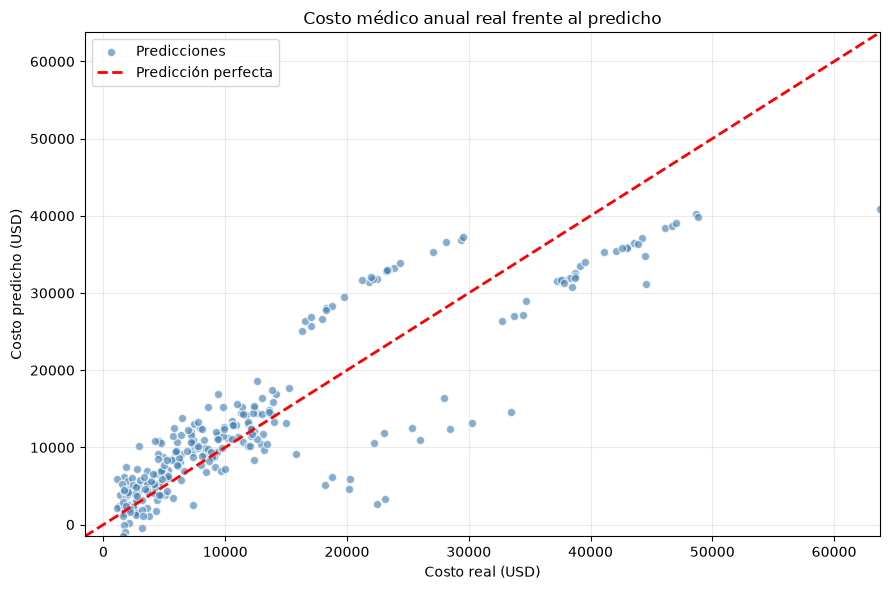

In [16]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.65,
    color="steelblue",
    edgecolors="white",
    label="Predicciones"
)

minimo = min(y_test.min(), y_pred.min())
maximo = max(y_test.max(), y_pred.max())

plt.plot(
    [minimo, maximo],
    [minimo, maximo],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Predicción perfecta"
)

plt.title("Costo médico anual real frente al predicho")
plt.xlabel("Costo real (USD)")
plt.ylabel("Costo predicho (USD)")

plt.xlim(minimo, maximo)
plt.ylim(minimo, maximo)

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### Comparación del error por rangos

Para complementar la lectura del gráfico, calculo el error absoluto
promedio en distintos rangos del costo real.

In [17]:
comparacion = pd.DataFrame({
    "Costo real": y_test,
    "Costo predicho": y_pred
})

comparacion["Error absoluto"] = (
    comparacion["Costo real"] - comparacion["Costo predicho"]
).abs()

comparacion["Rango de costo"] = pd.cut(
    comparacion["Costo real"],
    bins=[0, 10000, 20000, 30000, 40000, 70000],
    labels=[
        "0 a 10000",
        "10000 a 20000",
        "20000 a 30000",
        "30000 a 40000",
        "40000 a 70000"
    ]
)

resumen_rangos = comparacion.groupby(
    "Rango de costo",
    observed=True
).agg(
    Cantidad=("Error absoluto", "size"),
    MAE_USD=("Error absoluto", "mean")
)

display(resumen_rangos.round(2))

,Cantidad,MAE_USD
Rango de costo,,
0 a 10000,155,2345.91
10000 a 20000,56,3686.37
20000 a 30000,24,11545.91
30000 a 40000,17,7709.74
40000 a 70000,16,8896.22


### Respuestas

**¿En qué rango predice mejor y en cuál peor?**

Al comparar el error absoluto promedio, el modelo predice mejor
los costos de hasta 10000 dólares, con un MAE de 2345.91 dólares.

El mayor error promedio aparece entre 20000 y 30000 dólares,
con un MAE de 11545.91 dólares.

| Rango del costo real en USD | MAE en USD |
|---|---:|
| 0 a 10000 | 2345.91 |
| 10000 a 20000 | 3686.37 |
| 20000 a 30000 | 11545.91 |
| 30000 a 40000 | 7709.74 |
| 40000 a 70000 | 8896.22 |

**¿Qué significa estar por encima o por debajo de la diagonal?**

Los puntos por encima de la diagonal representan sobreestimaciones:
el costo predicho es mayor que el real.

Los puntos por debajo representan subestimaciones: el costo predicho
es menor que el real.

Hay puntos a ambos lados, pero los casos con los mayores errores
absolutos en esta prueba corresponden a subestimaciones.

**¿Se observan grupos separados?**

Se distinguen agrupaciones de puntos. Una posible explicación es
que existan perfiles de costos diferentes relacionados con el
tabaquismo y el IMC. El gráfico por sí solo no permite identificar
con seguridad a qué grupo pertenece cada punto.

**Hipótesis sobre los mayores errores**

Los mayores errores pueden aparecer en asegurados con gastos médicos
extraordinarios que el modelo no puede anticipar con estas variables.
No se dispone de información sobre enfermedades o tratamientos.

También puede influir que este modelo considere un efecto aditivo
del tabaquismo y del IMC, sin incluir una interacción entre ambos.

## Paso 09. Predecir el costo de nuevos solicitantes

Utilizo el modelo para predecir el costo anual de tres personas.
Los solicitantes A y B tienen las mismas características, excepto
que A fuma y B no.

In [19]:
solicitantes = pd.DataFrame({
    "age": [45, 45, 25],
    "sex": ["male", "male", "female"],
    "bmi": [33.5, 33.5, 22.0],
    "children": [2, 2, 0],
    "smoker": ["yes", "no", "no"],
    "region": ["southeast", "southeast", "northwest"]
}, index=["A", "B", "C"])

display(solicitantes)

,age,sex,bmi,children,smoker,region
A,45,male,33.5,2,yes,southeast
B,45,male,33.5,2,no,southeast
C,25,female,22.0,0,no,northwest


In [20]:
# Generar las columnas indicadoras de los nuevos solicitantes.
solicitantes_codificados = pd.get_dummies(
    solicitantes,
    dtype=int
)

# Usar exactamente las columnas y el orden del entrenamiento.
solicitantes_codificados = solicitantes_codificados.reindex(
    columns=X.columns,
    fill_value=0
)

display(solicitantes_codificados)

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
A,45,33.5,2,1,1,0,1,0
B,45,33.5,2,1,0,0,1,0
C,25,22.0,0,0,0,1,0,0


In [21]:
predicciones = modelo.predict(solicitantes_codificados)

resultados = solicitantes.copy()
resultados["Costo anual predicho (USD)"] = predicciones

display(resultados.round(2))

diferencia_ab = predicciones[0] - predicciones[1]

print(f"Diferencia entre A y B: {diferencia_ab:.2f} USD")
print(
    f"Coeficiente de smoker_yes: "
    f"{coeficientes['smoker_yes']:.2f} USD"
)

,age,sex,bmi,children,smoker,region,Costo anual predicho (USD)
A,45,male,33.5,2,yes,southeast,34750.52
B,45,male,33.5,2,no,southeast,11099.39
C,25,female,22.0,0,no,northwest,1538.53


Diferencia entre A y B: 23651.13 USD
Coeficiente de smoker_yes: 23651.13 USD


### Resultados

| Solicitante | Costo anual predicho |
|---|---:|
| A | 34750.52 USD |
| B | 11099.39 USD |
| C | 1538.53 USD |

### Respuestas

**¿Por qué es necesario reindex?**

Porque el modelo necesita recibir las mismas columnas y en el mismo
orden que utilizó durante el entrenamiento.

reindex agrega con cero las columnas que faltan y elimina las
columnas que no pertenecen a X.

**¿Qué ocurriría sin este paso?**

Los solicitantes nuevos no contienen todas las regiones presentes
en el dataset original. Por eso la codificación puede generar una
cantidad de columnas diferente.

Sin alinearlas, el modelo podría producir un error al recibir
variables distintas de las utilizadas en el entrenamiento.

Para los solicitantes nuevos genero las columnas indicadoras sin
drop_first=True y después selecciono las columnas de X. Esto conserva
las referencias del entrenamiento aunque alguna de esas categorías
no aparezca en los datos nuevos.

**¿Cuánto cambia la predicción entre A y B?**

La diferencia es de 23651.13 dólares:

$$
34750.518637 - 11099.389781 = 23651.128856\ \text{USD}
$$

Esta diferencia coincide con el coeficiente de smoker_yes.

Como A y B solamente se diferencian en la condición de fumador,
el cambio en la predicción corresponde completamente a esa variable.